In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Loading Data

In [5]:
import tensorflow
from tensorflow.keras import datasets,layers
(train_images,train_labels),(test_images,test_labels) = tensorflow.keras.datasets.fashion_mnist.load_data()

In [7]:
print(train_images.shape)
print(test_images.shape)

(60000, 28, 28)
(10000, 28, 28)


# We may want to create some labels for our labelled data

In [8]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Plotting some random images

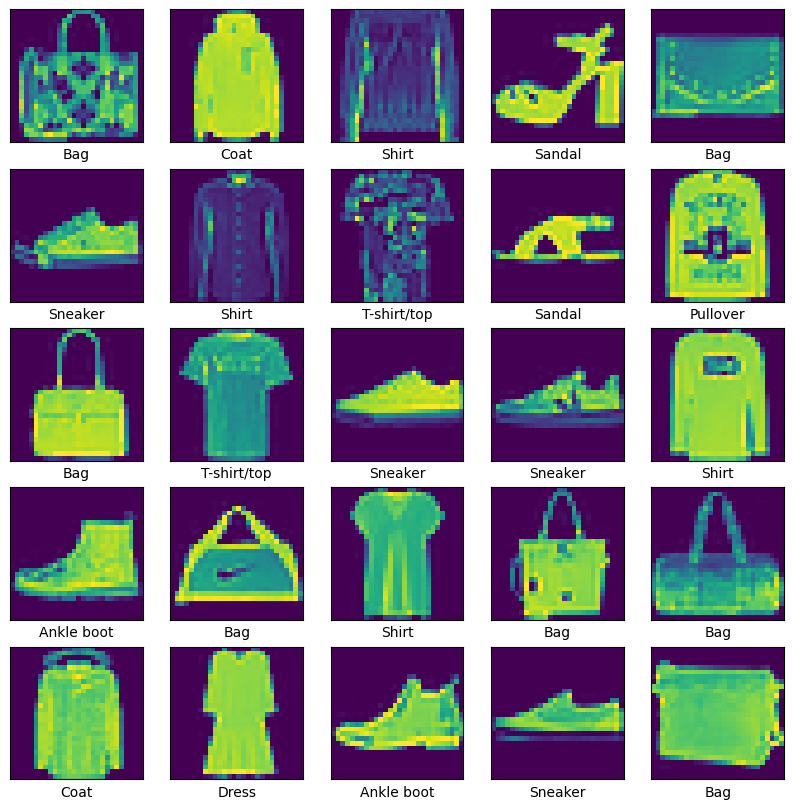

In [11]:
import random
plt.figure(figsize=(10,10))
for i in range(25):
  plt.subplot(5,5,i+1)
  plt.xticks([])
  plt.yticks([])
  num = random.randint(0,len(train_images))
  plt.imshow(train_images[num])
  plt.xlabel(class_names[train_labels[num]])
plt.show()

# We may want to check the distribution of the trained data

In [13]:
train_labels = train_labels.copy()
train_labels = pd.Series(train_labels)
train_labels.value_counts()

,count
9,6000
0,6000
3,6000
2,6000
7,6000
5,6000
1,6000
6,6000
4,6000
8,6000


From our observation all the classes are well reprsented in the datset

# Reshaping the images to be one dimensions

In [15]:
#train_reshaped = train_images.reshape(train_images.shape()[0],28,28,1)
#test_reshaped = test_images.reshape(test_images.shape()[0],28,28,1)

# Building a model

In [17]:
input_shape = (28,28,1)
model = tensorflow.keras.Sequential()
#convolution layer 1
model.add(layers.Conv2D(filters = 16,kernel_size = (3,3),strides = (1,1),activation="relu",padding = "valid",input_shape = input_shape))
model.add(layers.MaxPooling2D(pool_size = (2,2),strides = (2,2)))
# convolution layer 2
model.add(layers.Conv2D(filters = 32, kernel_size = (3,3),strides = (1,1),padding = "valid",activation = "relu",input_shape = input_shape))
model.add(layers.MaxPooling2D(pool_size = (2,2),strides = (2,2)))
#add a flattened layer
model.add(layers.Flatten())
#adding some layers with some drop out
model.add(layers.Dense(256,activation = "relu"))
model.add(layers.Dropout(0.3))
model.add(layers.Dense(128,activation = "relu"))
model.add(layers.Dropout(0.3))
# adding the output layer
model.add(layers.Dense(10,activation = "softmax"))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


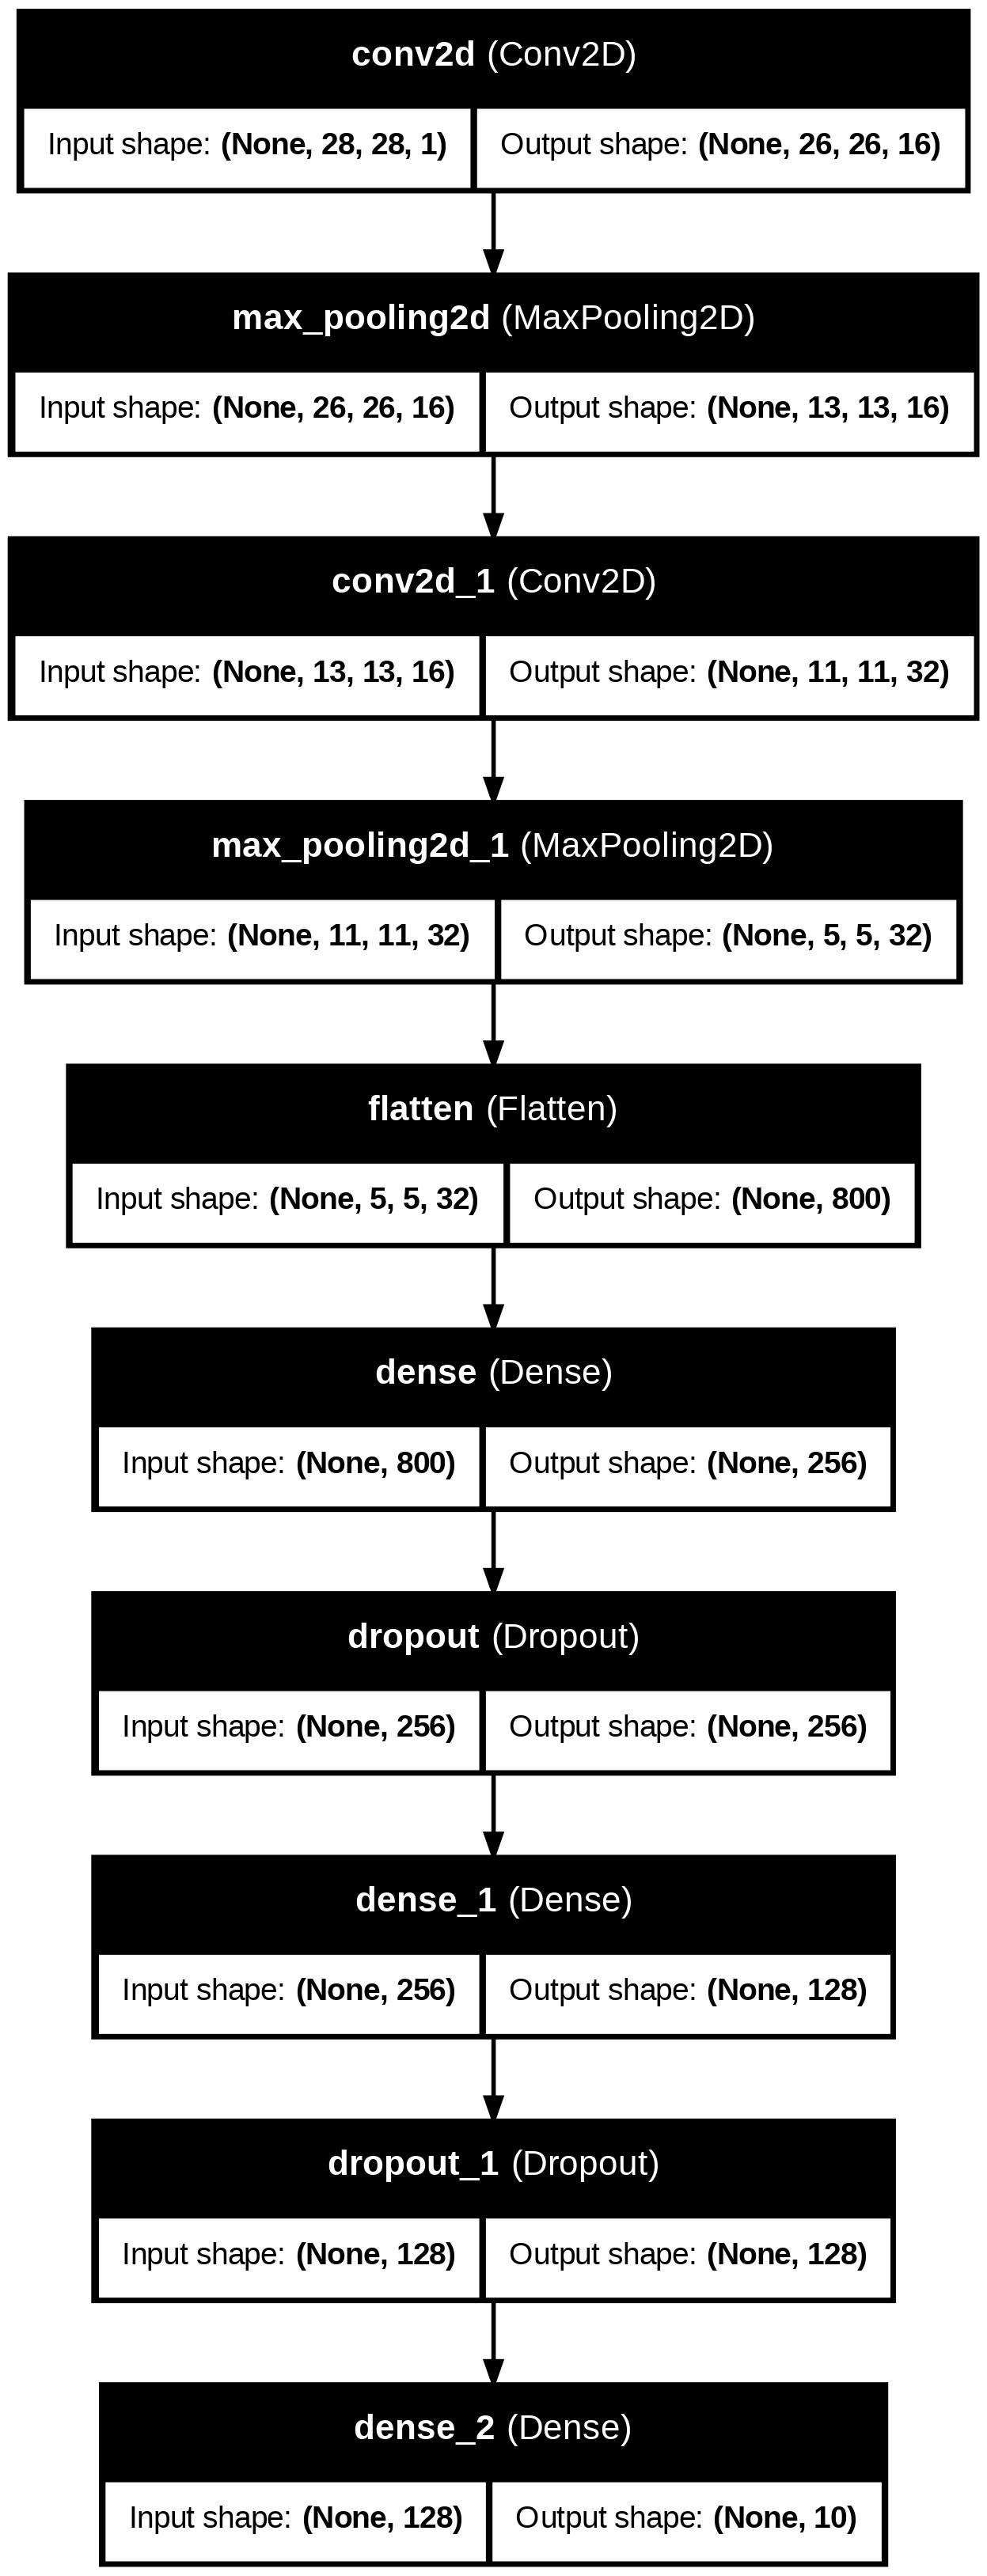

In [18]:
from tensorflow.keras.utils import plot_model
plot_model(model,show_layer_names = True,show_shapes = True)

# Summary of our model

In [20]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       205,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 244,042 (953.29 KB)

 Trainable params: 244,042 (953.29 KB)

 Non-trainable params: 0 (0.00 B)

# Model Training

# Normalizing our data to feed to our models

In [21]:
train_images = train_images / 255.0
test_images = test_images / 255.0

In [23]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor = "val_loss",patience = 3, restore_best_weights = True,verbose = 1)


In [24]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [25]:
history = model.fit(train_images, train_labels, epochs=10,validation_split=0.2, callbacks=[early_stopping],batch_size=100)
history

Epoch 1/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 24s 46ms/step - accuracy: 0.6447 - loss: 0.9663 - val_accuracy: 0.8299 - val_loss: 0.4418
Epoch 2/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 40s 46ms/step - accuracy: 0.8290 - loss: 0.4619 - val_accuracy: 0.8684 - val_loss: 0.3599
Epoch 3/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 41s 46ms/step - accuracy: 0.8623 - loss: 0.3708 - val_accuracy: 0.8778 - val_loss: 0.3288
Epoch 4/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 22s 46ms/step - accuracy: 0.8780 - loss: 0.3324 - val_accuracy: 0.8870 - val_loss: 0.3077
Epoch 5/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 23s 48ms/step - accuracy: 0.8878 - loss: 0.3121 - val_accuracy: 0.8932 - val_loss: 0.2905
Epoch 6/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 22s 46ms/step - accuracy: 0.8950 - loss: 0.2874 - val_accuracy: 0.8995 - val_loss: 0.2748
Epoch 7/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 41s 46ms/step - accuracy: 0.8991 - loss: 0.2719 - val_accuracy: 0.8942 - val_loss: 0.2895
Epoch 8/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 22s 46ms/step - accuracy: 0.9047 - loss: 0.2484 - 

In [26]:
history_df = pd.DataFrame(history.history)

<Axes: >

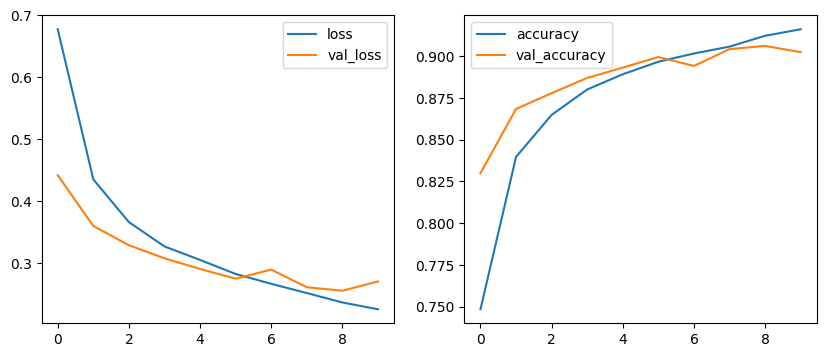

In [28]:
fig,ax = plt.subplots(1,2,figsize = (10,4))
history_df[['loss','val_loss']].plot(kind = "line",ax = ax[0])
history_df[['accuracy','val_accuracy']].plot(kind = "line",ax = ax[1])

# Model Evaluation on Test Data

In [29]:
predictions = model.predict(test_images)
predictions

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


array([[1.3564521e-08, 3.9131990e-08, 2.4748728e-08, ..., 3.6787093e-04,
        1.5259294e-08, 9.9951977e-01],
       [2.2960596e-06, 2.0065612e-11, 9.9983191e-01, ..., 2.4126467e-10,
        6.2000524e-08, 5.1590543e-10],
       [3.9988195e-12, 9.9999994e-01, 8.7889579e-15, ..., 3.4682370e-19,
        1.4200284e-16, 8.9516597e-19],
       ...,
       [2.4469466e-07, 7.3694204e-11, 7.2669154e-10, ..., 1.1985117e-09,
        9.9999958e-01, 1.1942493e-09],
       [4.1042153e-10, 9.9999994e-01, 4.4787070e-11, ..., 2.5849879e-14,
        9.8101128e-13, 5.5930229e-14],
       [3.4232181e-04, 1.2341850e-04, 3.2427476e-04, ..., 8.2348518e-02,
        1.1628562e-02, 3.4633717e-03]], dtype=float32)

Text(0.5, 0, 'Ankle boot')

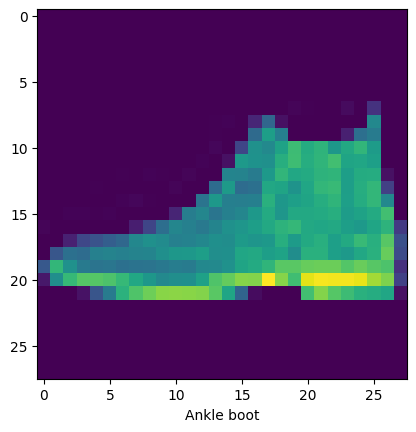

In [31]:
plt.imshow(test_images[0])
plt.xlabel(class_names[np.argmax(predictions[0])])

# Displaying our predictions

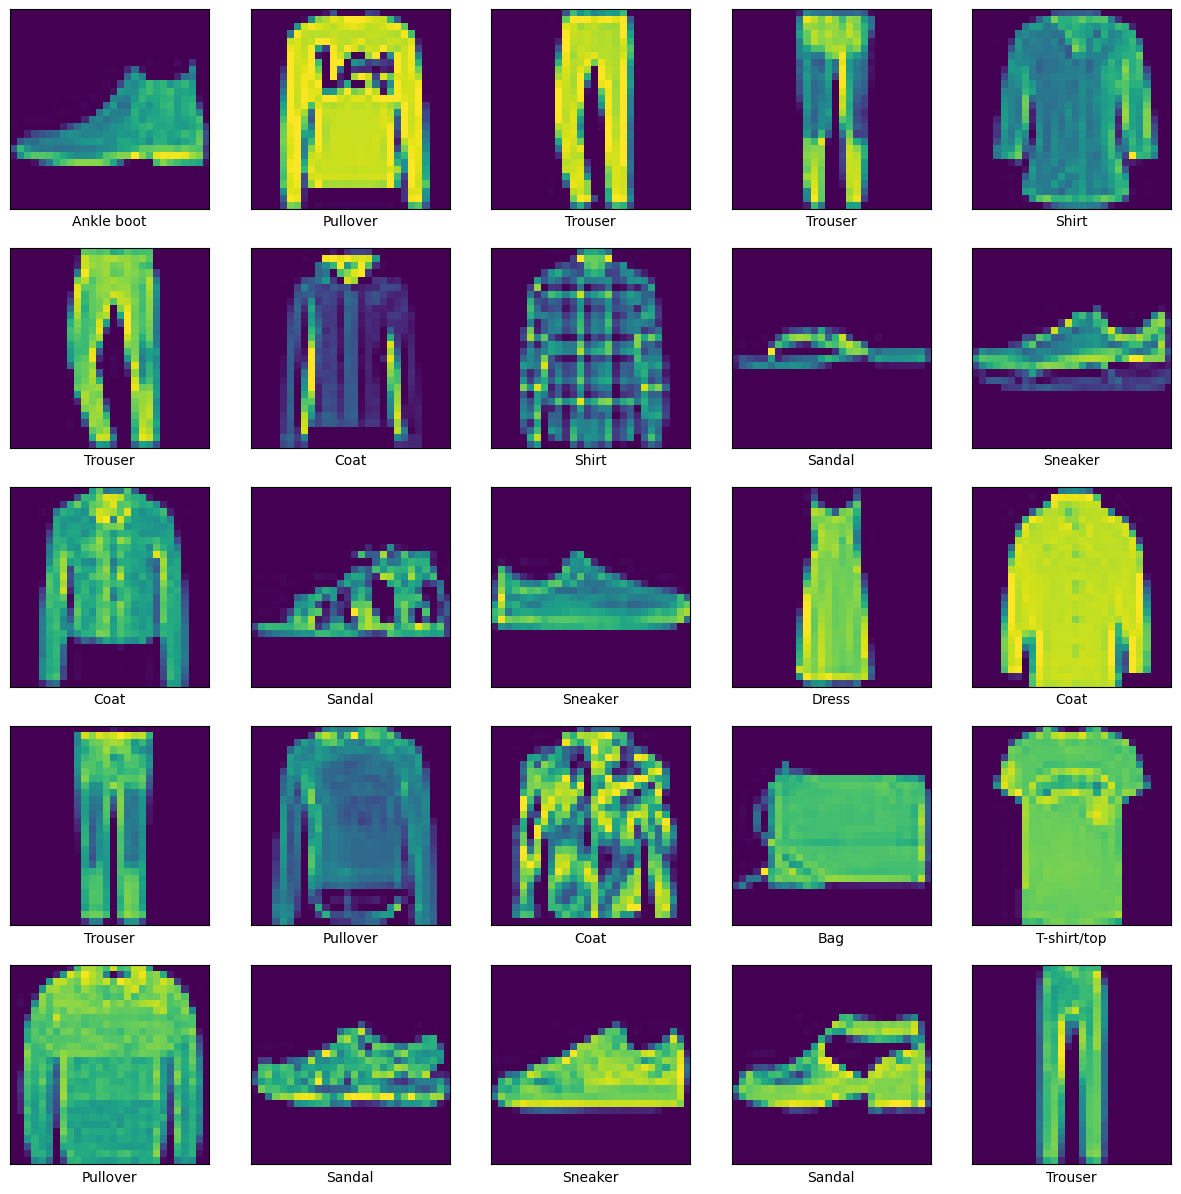

In [32]:
plt.figure(figsize=(15,15))
for i in range (25):
  plt.subplot(5,5,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(test_images[i])
  plt.xlabel(class_names[np.argmax(predictions[i])])
plt.show()

# Classification Report

In [34]:
from sklearn.metrics import classification_report
print(classification_report(test_labels,np.argmax(predictions,axis = 1),target_names=class_names))

              precision    recall  f1-score   support

 T-shirt/top       0.84      0.85      0.84      1000
     Trouser       0.98      0.98      0.98      1000
    Pullover       0.84      0.88      0.86      1000
       Dress       0.90      0.91      0.90      1000
        Coat       0.82      0.90      0.85      1000
      Sandal       0.99      0.97      0.98      1000
       Shirt       0.76      0.64      0.70      1000
     Sneaker       0.94      0.98      0.96      1000
         Bag       0.98      0.97      0.98      1000
  Ankle boot       0.97      0.96      0.97      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000

